# 01 · Data and exploratory analysis

**Question.** Can we put honest probabilities on UEFA Champions League outcomes, and does a neural network add anything over simple, well-understood baselines?

**Framing (why matches, not seasons).** A neural network cannot "foretell football", and a *season-level* model has only 34 labelled examples (one champion per edition) — far too few to train anything deep. The well-posed problem is therefore **match-level**: predict the 90-minute result (home / draw / away) from information available *before kick-off*. That gives ~4,100 labelled matches. Tournament-winner probabilities then come from a Monte-Carlo simulation of the bracket driven by those match probabilities (notebook 04), which is also how a forecaster would reason about a knockout format.

This notebook documents the data, checks its quality, and looks at the structure that the models must learn: home advantage, low-scoring games, and a heavy-tailed distribution of success.

## Data card

| | |
|---|---|
| **Sources** | [`footballcsv/europe-champions-league`](https://github.com/footballcsv/europe-champions-league) (seasons 1992/93 – 2010/11, CSV) and [`openfootball/champions-league`](https://github.com/openfootball/champions-league) (2011/12 – 2025/26, Football.TXT) |
| **Licence** | CC0 1.0 (public domain dedication) for both repositories — freely redistributable |
| **Access** | Plain HTTPS from `raw.githubusercontent.com`; **no login, no API key, no Kaggle token** |
| **Pinned versions** | footballcsv `66393c8d…`, openfootball `abfaeddc…` (git commits, so the bytes can never change); every file is verified against a SHA-256 in `src/ucl/checksums.json` |
| **First retrieved** | 2026-10-12 |
| **Scope kept** | Main competition only: group / league phase, knockout rounds, final. **Qualifying rounds are excluded** (hundreds of tiny clubs with almost no history) |
| **Target** | 90-minute result from the first-listed team's perspective. Extra time and penalties are stored but only used to decide who advances / wins the trophy |
| **Not available** | Venue, attendance, line-ups, injuries, betting odds, domestic-league form |

Both sources are parsed into one table by `ucl.data`. Club names are harmonised in `ucl.names` (e.g. `Bayern München`, `FC Bayern München` → one club); the alias table was built by listing all (country, name) pairs and merging variants by hand, and a unit test guards it.

**Cross-validation of the parsers.** The two repositories overlap on 2011/12 – 2014/15. Parsing both independently, **497 of 500 matches agree exactly on date, teams and 90-minute score, and the other 3 are finals that the two files list with the teams in opposite order** (their scores are mirror images). Since a final is played at a neutral venue the order carries no information, and the models treat it as such. This check is repeated in `tests/test_data.py`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from ucl import data
from ucl import plotting as P
from ucl.config import MATCHES_CSV, RAW_DIR, split_of_season

P.apply_style()
pd.set_option("display.width", 140)

In [2]:
# Idempotent: downloads only what is missing, verifies SHA-256, rebuilds the table.
data.download()
matches = data.build_matches()
MATCHES_CSV.parent.mkdir(parents=True, exist_ok=True)
matches.to_csv(MATCHES_CSV, index=False)

raw_mb = sum(p.stat().st_size for p in RAW_DIR.glob("*") if p.is_file()) / 1e6
display(
    Markdown(
        f"**{len(matches):,} matches**, {matches.season.nunique()} seasons "
        f"({matches.date.min():%d %b %Y} → {matches.date.max():%d %b %Y}), "
        f"{pd.concat([matches.home, matches.away]).nunique()} distinct clubs, "
        f"{matches.home_country.nunique()} associations. Raw download: {raw_mb:.1f} MB."
    )
)
matches.drop(columns=["et_home_goals", "et_away_goals", "pen_home", "pen_away", "source"]).head(4)

**4,127 matches**, 34 seasons (16 Sep 1992 → 30 May 2026), 180 distinct clubs, 42 associations. Raw download: 0.6 MB.

,match_id,season,date,stage,round,group,leg,home,away,home_country,away_country,home_goals,away_goals
0,0,1992,1992-09-16,knockout,Round 1,None,1.0,aek athens|GRE,apoel nikosia|CYP,GRE,CYP,1,1
1,1,1992,1992-09-16,knockout,Round 1,None,1.0,austria wien|AUT,cska sofia|BUL,AUT,BUL,3,1
2,2,1992,1992-09-16,knockout,Round 1,None,1.0,barcelona|ESP,viking|NOR,ESP,NOR,1,0
3,3,1992,1992-09-16,knockout,Round 1,None,1.0,glentoran|NIR,olympique marseille|FRA,NIR,FRA,0,5


### Quality checks

Cheap assertions that would catch a broken parse: each edition has exactly one final, the champion derived from the final's extra-time / penalty result must match common knowledge, no club plays itself, and per-season match counts must match the known formats (125 matches for the 32-team format, 189 for the 36-team league phase introduced in 2024/25, 157 for the two-group-stage era of 1999-2002, 119 for 2019/20 when the knockout rounds were single games in Lisbon).

In [3]:
winners = data.season_winners(matches)
per_season = matches.groupby("season").size()
assert (matches.home != matches.away).all()
assert matches[["home", "away", "home_goals", "away_goals"]].notna().all().all()
assert len(winners) == 34

fmt = per_season.value_counts().sort_index()
display(
    Markdown(
        "Matches per season, by format: "
        + ", ".join(f"**{n}** matches × {c} seasons" for n, c in fmt.items())
    )
)

champs = pd.Series(winners).map(lambda k: k.split("|")[0].title())
pd.DataFrame(
    {"season": [f"{s}/{(s + 1) % 100:02d}" for s in champs.index], "champion": champs.values}
).set_index("season").T

Matches per season, by format: **61** matches × 3 seasons, **74** matches × 1 seasons, **75** matches × 1 seasons, **85** matches × 2 seasons, **119** matches × 1 seasons, **125** matches × 20 seasons, **157** matches × 4 seasons, **189** matches × 2 seasons

season,1992/93,1993/94,1994/95,1995/96,1996/97,1997/98,1998/99,1999/00,2000/01,2001/02,...,2016/17,2017/18,2018/19,2019/20,2020/21,2021/22,2022/23,2023/24,2024/25,2025/26
champion,Olympique Marseille,Milan,Ajax,Juventus,Borussia Dortmund,Real Madrid,Manchester United,Real Madrid,Bayern Munchen,Real Madrid,...,Real Madrid,Real Madrid,Liverpool,Bayern Munchen,Chelsea,Real Madrid,Manchester City,Real Madrid,Paris Saint Germain,Paris Saint Germain


## What does the data look like?

Four views that drive modelling decisions: the changing tournament format (the league phase from 2024/25 is a distribution shift that lands in the test set), how large home advantage really is, how few goals are scored, and how concentrated titles are.

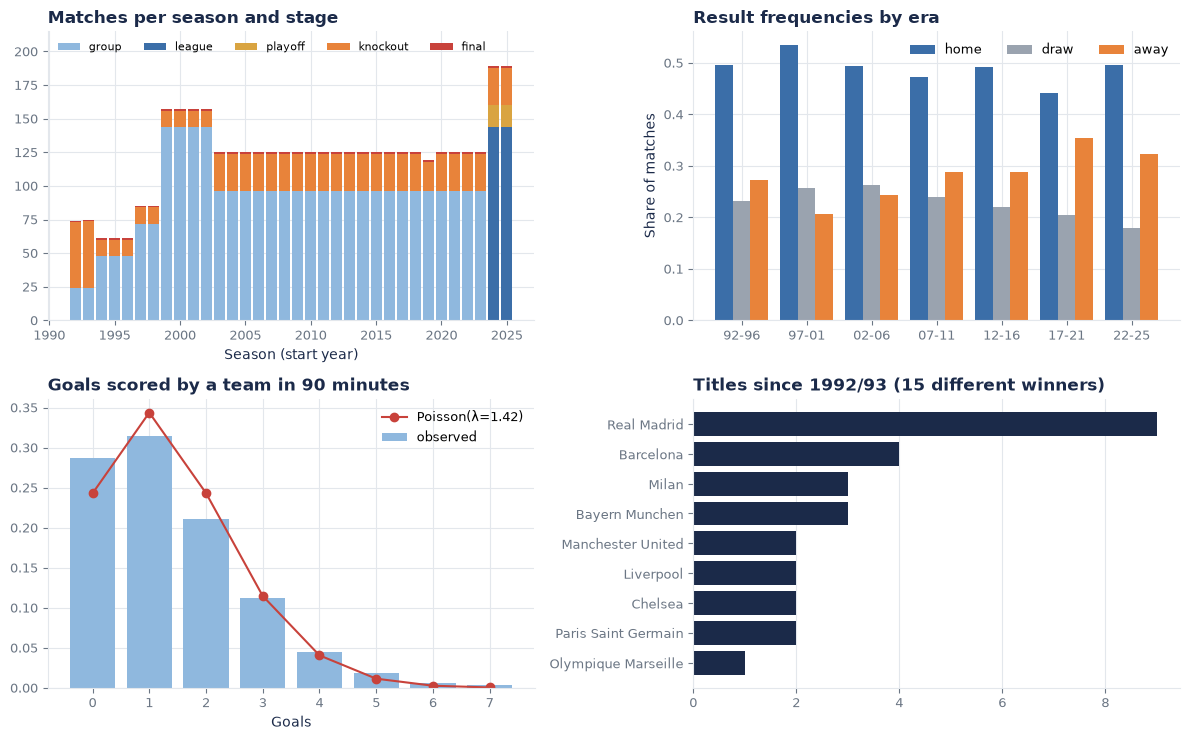

* Home / draw / away: **48.9% / 22.8% / 28.3%**; mean home goal difference **+0.47**. Draws have fallen from 26% (peak era) to 18% in 2022-25.
* Goals per team-match: mean 1.42, variance 1.80 (Poisson would give variance = mean) — **over-dispersed**: more goalless and more high-scoring team-games than a Poisson process, so the simulator samples goal margins from the empirical distribution rather than assuming Poisson.
* Top three clubs hold **16 of 34** titles; the winner distribution is heavy-tailed, so uniform (1/32) is a poor tournament baseline and good team-strength estimates matter.

In [4]:
from scipy.stats import poisson

fig, axes = plt.subplots(2, 2, figsize=(12, 7.5))

# (a) matches per season by stage
ax = axes[0, 0]
stage_order = ["group", "league", "playoff", "knockout", "final"]
stage_colors = [P.COLORS[c] for c in ("sky", "blue", "gold", "orange", "red")]
cnt = (
    matches.groupby(["season", "stage"])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=stage_order, fill_value=0)
)
bottom = np.zeros(len(cnt))
for st, col in zip(stage_order, stage_colors, strict=False):
    ax.bar(cnt.index, cnt[st], bottom=bottom, color=col, label=st, width=0.85)
    bottom += cnt[st].to_numpy()
ax.set_title("Matches per season and stage")
ax.set_xlabel("Season (start year)")
ax.legend(ncol=5, loc="upper left", fontsize=8)
ax.set_ylim(0, 215)

# (b) outcome rates by era (excluding neutral-venue finals)
ax = axes[0, 1]
m = matches[matches.stage != "final"].copy()
m["era"] = pd.cut(
    m.season,
    [1991, 1996, 2001, 2006, 2011, 2016, 2021, 2025],
    labels=["92-96", "97-01", "02-06", "07-11", "12-16", "17-21", "22-25"],
)
m["res"] = np.sign(m.home_goals - m.away_goals).map({1: "home", 0: "draw", -1: "away"})
rate = m.groupby("era", observed=True).res.value_counts(normalize=True).unstack()[["home", "draw", "away"]]
x = np.arange(len(rate))
w = 0.27
for i, k in enumerate(["home", "draw", "away"]):
    ax.bar(x + (i - 1) * w, rate[k], w, color=P.OUTCOME_COLORS[k], label=k)
ax.set_xticks(x, rate.index)
ax.set_title("Result frequencies by era")
ax.legend(ncol=3)
ax.set_ylabel("Share of matches")

# (c) goals per team per match vs Poisson
ax = axes[1, 0]
g = pd.concat([matches.home_goals, matches.away_goals])
k = np.arange(0, 8)

ax.bar(k, [(g == i).mean() for i in k], color=P.COLORS["sky"], label="observed")
ax.plot(k, poisson.pmf(k, g.mean()), "o-", color=P.COLORS["red"], label=f"Poisson(λ={g.mean():.2f})")
ax.set_title("Goals scored by a team in 90 minutes")
ax.set_xlabel("Goals")
ax.legend()

# (d) titles
ax = axes[1, 1]
titles = pd.Series(winners).map(lambda k: k.split("|")[0].title()).value_counts()
top = titles.head(9)[::-1]
ax.barh(top.index, top.values, color=P.COLORS["navy"])
ax.set_title(f"Titles since 1992/93 ({titles.size} different winners)")
ax.grid(axis="y", visible=False)
fig.tight_layout()
P.save(fig, "eda_overview")
plt.show()

hd = (m.home_goals - m.away_goals).mean()
display(
    Markdown(
        f"* Home / draw / away: **{(m.res == 'home').mean():.1%} / {(m.res == 'draw').mean():.1%} / {(m.res == 'away').mean():.1%}**; "
        f"mean home goal difference **{hd:+.2f}**. Draws have fallen from {rate.draw.max():.0%} (peak era) to {rate.draw.iloc[-1]:.0%} in 2022-25.\n"
        f"* Goals per team-match: mean {g.mean():.2f}, variance {g.var():.2f} (Poisson would give variance = mean) — **over-dispersed**: more goalless and more high-scoring team-games than a Poisson process, so the simulator samples goal margins from the empirical distribution rather than assuming Poisson.\n"
        f"* Top three clubs hold **{titles.head(3).sum()} of {titles.sum()}** titles; the winner distribution is heavy-tailed, so uniform (1/32) is a poor tournament baseline and good team-strength estimates matter."
    )
)

**Reading the figure.**

* *(a)* The format changes are visible: 157-match editions in 1999-2002 (two group stages), a long 125-match plateau, and 189 matches from 2024/25 (league phase + play-offs). The test period straddles this change, so part of what we measure is robustness to a format shift.
* *(b)* Home advantage is real (about 49% home wins vs 28% away) but not constant: the home share dips in 2017-21, an era that includes the 2020/21 season played largely behind closed doors, and recovers afterwards. Draws became markedly rarer over the decades. The data has no venue / crowd information, so such regime changes are a source of irreducible error.
* *(c)* Goals are over-dispersed relative to Poisson (excess of 0-0 type scores and of blow-outs); the team-level Poisson shape is only a rough guide.
* *(d)* A handful of clubs win most titles, so even a trivial "pick a historical giant" strategy would look decent — which is exactly why probabilistic scoring against baselines is needed.

## Chronological split

All model selection respects time. The split is by **season**, never random:

| split | seasons | role |
|---|---|---|
| train | 1992/93 – 2016/17 | fit model parameters |
| validation | 2017/18 – 2020/21 | early stopping, hyper-parameters, temperature scaling |
| test | 2021/22 – 2025/26 | touched once, for the numbers we report |

Features for a test match may use *earlier* test matches (a rating keeps updating as the season unfolds — that is simply how forecasting works in production), but model **parameters** never see them.

In [5]:
split = matches.season.map(split_of_season)
tab = matches.groupby(split).agg(
    matches=("match_id", "size"), first=("date", "min"), last=("date", "max"), seasons=("season", "nunique")
)
tab = tab.loc[["train", "val", "test"]]
tab["share"] = (tab.matches / tab.matches.sum()).map("{:.0%}".format)
tab["first"] = tab["first"].dt.date
tab["last"] = tab["last"].dt.date
tab

,matches,first,last,seasons,share
season,,,,,
train,2880,1992-09-16,2017-06-03,25,70%
val,494,2017-09-12,2021-05-29,4,12%
test,753,2021-09-14,2026-05-30,5,18%


Only ~2,900 training matches: that is small data for deep learning, which sets realistic expectations for notebook 03. Next: turn raw matches into leakage-free features and build the baselines.